# Interference-Aware Write Control for Bounded-Memory Recurrent Models — results notebook (RP3)

Ryan Ellis, EN.705.742, Johns Hopkins University, Fall 2026.

This notebook regenerates every number-bearing artefact of the final paper from the run files
shipped in `paper/runs/` (one directory per run: `results.json`, `log.txt`, the per-sequence
recall arrays `per_example_L*.npy`, and for audited runs `gate_audit.json`), reproduces the
capacity analysis, runs the unit tests, and trains one small model end to end so the pipeline
can be seen working. Run it from the repository root with the `jhu-742` kernel (PyTorch,
flash-linear-attention). Every cell is read-only with respect to the shipped run files.

In [1]:
import sys, json, subprocess, pathlib, time
ROOT = pathlib.Path.cwd()
assert (ROOT / "paper" / "runs").is_dir(), "run from the repository root"
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "experiments")); sys.path.insert(0, str(ROOT / "experiments" / "analysis"))
import torch, numpy as np
print("torch", torch.__version__, "| cuda", torch.cuda.is_available(), "| run dirs:", len(list((ROOT / "paper" / "runs").iterdir())))

torch 2.11.0+cu128 | cuda True | run dirs: 243


## 1. Table III (primary result) and the hypothesis verdicts

Rows are generated by the same function the paper uses (`experiments/analysis/sweep_paper.py`), from `paper/runs/`.

In [2]:
import sweep_table, sweep_paper
runs = sweep_table.load(ROOT / "paper" / "runs")
h2 = sweep_paper.load_h2([ROOT / "paper" / "runs"])
print(sweep_paper.tex_rows(runs, h2))

Controller & 22.9 {\scriptsize$\pm$6.7} & 63.5 {\scriptsize$\pm$0.8} & 66.8 {\scriptsize$\pm$16.6} & 6.5 {\scriptsize$\pm$5.6} & 23.7 {\scriptsize$\pm$7.6} & 39.8 {\scriptsize$\pm$12.9} \\
Novelty ablation & 27.7 {\scriptsize$\pm$4.1} & 45.6 {\scriptsize$\pm$9.9} & 77.3 {\scriptsize$\pm$13.5} & 10.8 {\scriptsize$\pm$9.3} & 31.8 {\scriptsize$\pm$0.7} & 61.7 {\scriptsize$\pm$2.9} \\
Pair-only recency & 40.1 {\scriptsize$\pm$0.0} & 70.1 {\scriptsize$\pm$0.0} & 100.0 {\scriptsize$\pm$0.0} & 25.1 {\scriptsize$\pm$0.0} & 40.0 {\scriptsize$\pm$0.0} & 70.0 {\scriptsize$\pm$0.0} \\
Recency & 0.0 {\scriptsize$\pm$0.0} & 0.0 {\scriptsize$\pm$0.0} & 29.0 {\scriptsize$\pm$0.0} & 0.0 {\scriptsize$\pm$0.0} & 0.0 {\scriptsize$\pm$0.0} & 0.0 {\scriptsize$\pm$0.0} \\
Residual cache & 30.2 {\scriptsize$\pm$12.6} & 0.2 {\scriptsize$\pm$0.4} & 0.0 {\scriptsize$\pm$0.0} & 5.3 {\scriptsize$\pm$9.1} & 3.5 {\scriptsize$\pm$6.0} & 0.1 {\scriptsize$\pm$0.2} \\
Position activation & 0.0 {\scriptsize$\pm$0.0} & 0.

In [3]:
# Verdicts by the pre-registered rule (paper IV-A): seed-level 95% t-interval of the per-seed differences.
for n in (64, 128):
    L = f"L{512 if n == 64 else 1024}"
    for s in (32, 64, 128):
        best = max((w for w in sweep_table.NONLEARNED if (w, s, n) in runs), key=lambda w: sweep_table.mean_recall(runs[(w, s, n)], L))
        r = sweep_table.paired(runs, "controller", best, s, n, L)
        lo, hi = sweep_table.seed_interval(r[3])
        print(f"H1  N={n:3d} S={s:3d}: controller - {best:13s} = {r[0]:+6.1f} pp  seed interval [{lo:+6.1f}, {hi:+6.1f}]  per seed {[round(d,1) for d in r[3]]}  -> {sweep_table.verdict(r[3], 5.0)}")
for s in (64, 128):
    a, b = h2[("input_only", "3e-4", s, 64)], runs[("controller", s, 64)]
    r = sweep_paper.paired_recs(b, a, "L512")  # controller minus input-only, equal rate
    lo, hi = sweep_table.seed_interval(r[3])
    print(f"H2  N= 64 S={s:3d}: controller - input_only (3e-4) = {r[0]:+6.1f} pp  seed interval [{lo:+6.1f}, {hi:+6.1f}]  per seed {[round(d,1) for d in r[3]]}  -> {sweep_table.verdict(r[3], 0.0)}")

H1  N= 64 S= 32: controller - pair_recency  =  -17.2 pp  seed interval [ -33.8,   -0.6]  per seed [-20.8, -21.2, -9.5]  -> reversed


H1  N= 64 S= 64: controller - pair_recency  =   -6.6 pp  seed interval [  -8.5,   -4.6]  per seed [-6.5, -5.8, -7.4]  -> reversed


H1  N= 64 S=128: controller - pair_recency  =  -33.2 pp  seed interval [ -74.4,   +8.0]  per seed [-52.3, -24.9, -22.4]  -> not supported


H1  N=128 S= 32: controller - pair_recency  =  -18.6 pp  seed interval [ -32.5,   -4.8]  per seed [-25.0, -15.7, -15.1]  -> reversed


H1  N=128 S= 64: controller - pair_recency  =  -16.3 pp  seed interval [ -35.2,   +2.5]  per seed [-7.6, -20.9, -20.5]  -> not supported


H1  N=128 S=128: controller - pair_recency  =  -30.2 pp  seed interval [ -62.1,   +1.8]  per seed [-15.4, -38.8, -36.3]  -> not supported


H2  N= 64 S= 64: controller - input_only (3e-4) =   -2.5 pp  seed interval [  -4.1,   -0.8]  per seed [-2.5, -1.8, -3.1]  -> reversed


H2  N= 64 S=128: controller - input_only (3e-4) =  -27.2 pp  seed interval [ -67.4,  +13.0]  per seed [-45.7, -20.5, -15.4]  -> not supported


## 2. Capacity analysis (Table II)

Closed forms for the three idealized policies, checked against a replay of the generator.

In [4]:
import ceiling
for N, L in ((64, 512), (128, 1024)):
    for S in (32, 64, 128):
        U = D = N // 4
        cf = ceiling.closed_form(S, N, U, D)
        sim = ceiling.ceiling(S, N, U, D, L, n=300, inplace=False), ceiling.ceiling(S, N, U, D, L, n=300), ceiling.ceiling(S, N, U, D, L, n=300, reject=True)
        meas = sweep_table.mean_recall(runs[("pair_recency", S, N)], f"L{L}")
        print(f"N={N:3d} S={S:3d}  pair-only closed {100*cf['pair_only']:5.1f} sim {100*sim[0]:5.1f} measured {meas:5.1f} | in-place closed {100*cf['in_place']:5.1f} sim {100*sim[1]:5.1f} | bound {100*cf['foreknowledge']:5.1f} sim {100*sim[2]:5.1f} | H1 margin {100*cf['h1_margin']:4.1f} (in-place part {100*cf['in_place_margin']:4.1f})")

N= 64 S= 32  pair-only closed  40.0 sim  40.1 measured  40.1 | in-place closed  43.8 sim  43.4 | bound  50.0 sim  50.0 | H1 margin 10.0 (in-place part  3.7)


N= 64 S= 64  pair-only closed  70.0 sim  70.0 measured  70.1 | in-place closed  81.2 sim  81.2 | bound 100.0 sim 100.0 | H1 margin 30.0 (in-place part 11.3)


N= 64 S=128  pair-only closed 100.0 sim 100.0 measured 100.0 | in-place closed 100.0 sim 100.0 | bound 100.0 sim 100.0 | H1 margin  0.0 (in-place part  0.0)


N=128 S= 32  pair-only closed  25.0 sim  25.0 measured  25.1 | in-place closed  25.0 sim  24.4 | bound  25.0 sim  25.0 | H1 margin  0.0 (in-place part  0.0)


N=128 S= 64  pair-only closed  40.0 sim  40.0 measured  40.0 | in-place closed  43.8 sim  43.4 | bound  50.0 sim  50.0 | H1 margin 10.0 (in-place part  3.7)


N=128 S=128  pair-only closed  70.0 sim  69.9 measured  70.0 | in-place closed  81.2 sim  81.0 | bound 100.0 sim 100.0 | H1 margin 30.0 (in-place part 11.3)


## 3. Figures 2 and 3

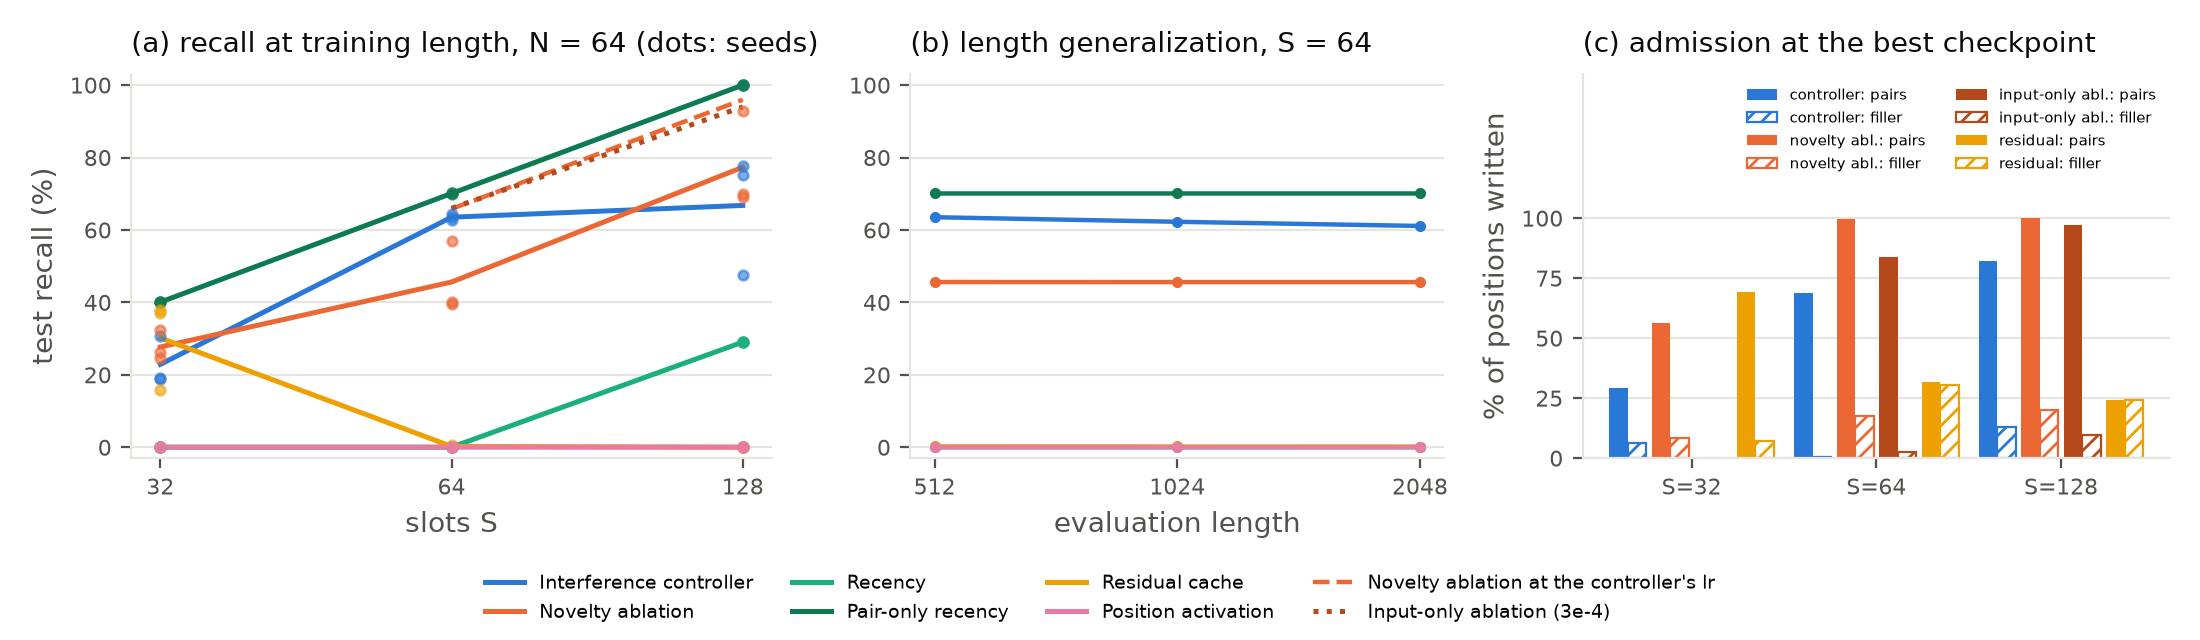

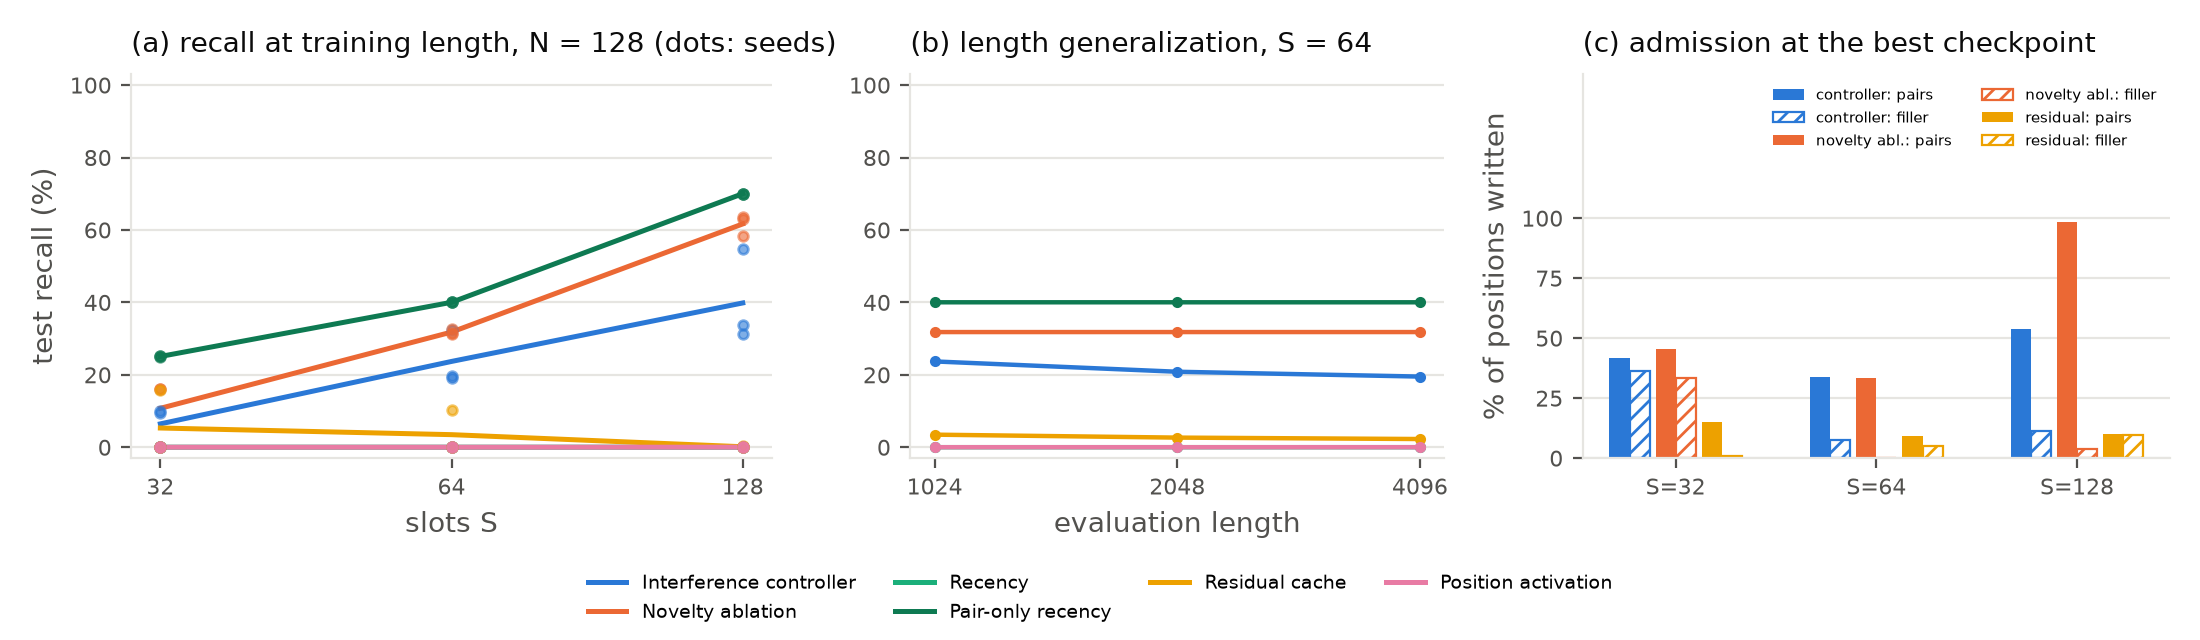

In [5]:
from IPython.display import Image, display
out = ROOT / "paper" / "build"; out.mkdir(exist_ok=True)
sweep_paper.figure(runs, out / "nb_sweep_n64.png", n=64, h2=h2)
sweep_paper.figure(runs, out / "nb_sweep_n128.png", n=128)
display(Image(str(out / "nb_sweep_n64.png"))); display(Image(str(out / "nb_sweep_n128.png")))

## 4. Gate audit: admission and in-place update handling

From `gate_audit.json` (one validation batch replayed through each run's best checkpoint).

In [6]:
rows = []
for d in sorted((ROOT / "paper" / "runs").iterdir()):
    g = d / "gate_audit.json"
    if g.exists():
        st = json.loads(g.read_text()); c = st["write_by_class"]
        rows.append((d.name, st["write_frac"], c["queried"], c["other"], st["update_key_present"], st["update_in_place"]))
print(f"{'run':44s} write_frac pairs filler upd_held in_place")
for r in rows: print(f"{r[0]:44s} {r[1]:9.2f} {r[2]:5.2f} {r[3]:6.3f} {r[4]:8.2f} {r[5]:8.2f}")
ctrl = [r[5] for r in rows if r[0].startswith("controller_")]
print(f"\ncontroller in-place rate over {len(ctrl)} runs: max {max(ctrl):.2f}")

run                                          write_frac pairs filler upd_held in_place
controller_S128_N64_s0                            0.31  0.63  0.234     0.49     0.00
controller_S128_N64_s1                            0.29  0.90  0.150     0.83     0.00
controller_S128_N64_s2                            0.18  0.92  0.005     0.82     0.00
controller_S64_N64_s0                             0.13  0.69  0.003     0.67     0.00
controller_S64_N64_s1                             0.13  0.69  0.003     0.67     0.00
controller_S64_N64_s2                             0.13  0.68  0.009     0.66     0.00
h2_controller_lr1e-3_S128_N64_s0                  0.29  0.95  0.150     0.81     0.00
h2_controller_lr1e-3_S128_N64_s1                  0.32  0.93  0.191     0.74     0.00
h2_controller_lr1e-3_S128_N64_s2                  0.32  0.98  0.166     0.81     0.00
h2_controller_lr1e-3_S64_N64_s0                   0.21  0.86  0.059     0.53     0.00
h2_controller_lr1e-3_S64_N64_s1                   0.1

## 5. Unit tests (CPU + a few GPU smoke tests)

In [7]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "-x", "tests"], capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-1500:])
assert r.returncode == 0, "tests failed"

.....................................................                    [100%]
=============================== warnings summary ===============================
../../../venvs/jhu-742/lib/python3.13/site-packages/torch/jit/_script.py:365: 14 warnings
  /home/ryan/venvs/jhu-742/lib/python3.13/site-packages/torch/jit/_script.py:365: DeprecationWarning: `torch.jit.script_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
    warnings.warn(

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
53 passed, 1 deselected, 14 warnings in 34.66s



## 6. One small training run, end to end

A two-minute demonstration on an 8-pair task (8 queried pairs, 2 updates, 2 distractors, 8 slots, length 64): the pair-only rule against the controller, 800 steps each. One seed at a toy scale; it makes no claim and shows the pipeline the sweep used.

In [8]:
from bmem.data import MQARConfig, make_splits
from bmem.model import ModelConfig, RecallModel
from bmem.train import TrainConfig, train, evaluate
if torch.cuda.is_available():
    dev = torch.device("cuda")
    dcfg = MQARConfig(vocab_size=512, seq_len=64, num_kv_pairs=8, num_updates=2, num_distractors=2)
    for writer in ("pair_recency", "controller"):
        torch.manual_seed(0)
        splits = make_splits(dcfg, 20000, 500, 1000, seed=0)
        m = RecallModel(ModelConfig(vocab_size=512, d_model=128, n_layers=2, n_heads=4, slots=8, mem_dim=64, writer=writer, pair_block=dcfg.context_tokens(), controller_hidden=32))
        t0 = time.time()
        stats = train(m, splits["train"], splits["val"], TrainConfig(steps=800, batch_size=64, lr=1e-3, warmup=50, eval_every=400, eval_batches=4, seed=0), dev, log=lambda *_: None)
        ev = evaluate(m.to(dev), splits["test"], dev, batch_size=128)
        print(f"{writer:13s} test recall {100*ev['recall']:5.1f}% after 800 steps ({time.time()-t0:.0f} s)")
else:
    print("no GPU: training demo skipped")

pair_recency  test recall  70.1% after 800 steps (20 s)


controller    test recall  39.2% after 800 steps (63 s)
